## EEG-Based Classification of Parkinson’s Disease vs Healthy Controls Using Resting-State EEG from OpenNeuro

In [1]:
import warnings
from pathlib import Path
import pandas as pd
import mne
import matplotlib.pyplot as plt

mne.set_log_level("WARNING")

## 0. Dataset loading, inspection and organization
### 0.1 Load dataset and build subject inventory

The EEG dataset is not included in this repository. Download the original dataset using the source provided in the README and place it in ../data/ds004584/ before running the notebook.

In [2]:
DATA_ROOT = Path("data/ds004584")

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_ROOT.resolve()}. "
        "Please download the dataset and place it in the expected directory."
    )

def build_subject_inventory(root_dir: Path):
    records = []

    for subject_dir in sorted(root_dir.glob("sub-*")):
        if not subject_dir.is_dir():
            continue

        subject_id = subject_dir.name
        eeg_dir = subject_dir / "eeg"

        if not eeg_dir.exists():
            records.append({
                "subject_id": subject_id,
                "eeg_dir": None,
                "set_file": None,
                "n_set_files": 0
            })
            continue

        set_files = sorted(eeg_dir.glob("*_eeg.set"))

        records.append({
            "subject_id": subject_id,
            "eeg_dir": str(eeg_dir),
            "set_file": str(set_files[0]) if len(set_files) == 1 else None,
            "n_set_files": len(set_files)
        })

    inventory = pd.DataFrame(records)
    return inventory

inventory = build_subject_inventory(DATA_ROOT)

print(f"Subjects found: {len(inventory)}")
print(inventory.head(10))

Subjects found: 149
  subject_id                    eeg_dir  \
0    sub-001  data/ds004584/sub-001/eeg   
1    sub-002  data/ds004584/sub-002/eeg   
2    sub-003  data/ds004584/sub-003/eeg   
3    sub-004  data/ds004584/sub-004/eeg   
4    sub-005  data/ds004584/sub-005/eeg   
5    sub-006  data/ds004584/sub-006/eeg   
6    sub-007  data/ds004584/sub-007/eeg   
7    sub-008  data/ds004584/sub-008/eeg   
8    sub-009  data/ds004584/sub-009/eeg   
9    sub-010  data/ds004584/sub-010/eeg   

                                            set_file  n_set_files  
0  data/ds004584/sub-001/eeg/sub-001_task-Rest_ee...            1  
1  data/ds004584/sub-002/eeg/sub-002_task-Rest_ee...            1  
2  data/ds004584/sub-003/eeg/sub-003_task-Rest_ee...            1  
3  data/ds004584/sub-004/eeg/sub-004_task-Rest_ee...            1  
4  data/ds004584/sub-005/eeg/sub-005_task-Rest_ee...            1  
5  data/ds004584/sub-006/eeg/sub-006_task-Rest_ee...            1  
6  data/ds004584/sub-007/eeg/s

### 0.2 Inspect channel consistency across subjects

In [3]:
def load_subject_raw(subject_id: str, inventory_df: pd.DataFrame):
    row = inventory_df.loc[inventory_df["subject_id"] == subject_id]

    if row.empty:
        raise ValueError(f"Subject {subject_id} not found.")

    set_file = row.iloc[0]["set_file"]

    if pd.isna(set_file) or set_file is None:
        raise ValueError(f"Subject {subject_id} does not have a unique .set file.")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        raw = mne.io.read_raw_eeglab(set_file, preload=False, verbose=False)
    return raw

def summarize_subject(raw, subject_id: str):
    summary = {
        "subject_id": subject_id,
        "n_channels": len(raw.ch_names),
        "sfreq": raw.info["sfreq"],
        "duration_sec": raw.n_times / raw.info["sfreq"],
        "channel_names_preview": raw.ch_names[:10]
    }
    return summary

raw_001 = load_subject_raw("sub-001", inventory)
summary_001 = summarize_subject(raw_001, "sub-001")

summary_001

{'subject_id': 'sub-001',
 'n_channels': 63,
 'sfreq': 500.0,
 'duration_sec': np.float64(281.66),
 'channel_names_preview': ['Fp1',
  'Fz',
  'F3',
  'F7',
  'FT9',
  'FC5',
  'FC1',
  'C3',
  'T7',
  'TP9']}

In [4]:
channel_pattern_records = []

for subject_id in inventory["subject_id"]:
    raw = load_subject_raw(subject_id, inventory)
    channel_tuple = tuple(sorted(raw.ch_names))
    channel_pattern_records.append({
        "subject_id": subject_id,
        "n_channels": len(raw.ch_names),
        "channel_pattern": channel_tuple
    })

channel_patterns_df = pd.DataFrame(channel_pattern_records)

pattern_summary = (
    channel_patterns_df
    .groupby(["n_channels", "channel_pattern"])
    .size()
    .reset_index(name="n_subjects")
    .sort_values("n_subjects", ascending=False)
)

pattern_summary[["n_channels", "n_subjects"]].head(10)

,n_channels,n_subjects
1,63,109
2,64,29
0,63,10
3,66,1


In [5]:
pattern_summary_detailed = (
    channel_patterns_df
    .groupby(["n_channels", "channel_pattern"])
    .size()
    .reset_index(name="n_subjects")
    .sort_values(["n_subjects", "n_channels"], ascending=[False, True])
    .reset_index(drop=True)
)

pattern_summary_detailed.head(10)

,n_channels,channel_pattern,n_subjects
0,63,"(AF3, AF4, AF7, AF8, AFz, C1, C2, C3, C4, C5, ...",109
1,64,"(AF3, AF4, AF7, AF8, AFz, C1, C2, C3, C4, C5, ...",29
2,63,"(AF3, AF4, AF7, AF8, AFz, C1, C2, C3, C4, C5, ...",10
3,66,"(AF3, AF4, AF7, AF8, AFz, C1, C2, C3, C4, C5, ...",1


In [12]:
COMMON_CHANNELS = ['AF3', 'AF4', 'AF7', 'AF8', 'AFz', 'C1', 'C2', 'C3', 'C4', 'C5',
                   'C6', 'CP1', 'CP2', 'CP3', 'CP4', 'CP5', 'CP6', 'CPz', 'Cz', 'F1',
                   'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'FC1', 'FC2', 'FC3',
                   'FC4', 'FC5', 'FC6', 'FCz', 'FT10', 'FT7', 'FT8', 'Fp1', 'Fp2',
                   'Fz', 'O1', 'O2', 'Oz', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7',
                   'P8', 'PO7', 'PO8', 'POz', 'T7', 'T8', 'TP10', 'TP7', 'TP8', 'TP9']

def load_subject_standard(subject_id: str, inventory_df: pd.DataFrame, common_channels: list):
    row = inventory_df.loc[inventory_df["subject_id"] == subject_id]

    if row.empty:
        raise ValueError(f"Subject {subject_id} not found.")

    set_file = row.iloc[0]["set_file"]

    if pd.isna(set_file) or set_file is None:
        raise ValueError(f"Subject {subject_id} does not have a unique .set file.")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        raw = mne.io.read_raw_eeglab(set_file, preload=True, verbose=False)

    # Keep only channels shared by all subjects
    keep_channels = [ch for ch in raw.ch_names if ch in common_channels]
    raw.pick(keep_channels)

    # Reorder to the same channel order every time
    raw.reorder_channels(common_channels)

    return raw

### 0.3 Integrate labels and build master table

In [13]:
participants = pd.read_csv(DATA_ROOT / "participants.tsv", sep="\t")
print(participants.head())

participants["GROUP"].value_counts(dropna=False)

participants = participants.rename(columns={"participant_id": "subject_id"})

inventory_master = inventory.merge(
    participants,
    on="subject_id",
    how="left"
)

inventory_master["target"] = inventory_master["GROUP"].map({
    "Control": 0,
    "PD": 1
})

master_cols = ["subject_id", "set_file", "GROUP", "target"]
master_table = inventory_master[master_cols].copy()

print(master_table["GROUP"].value_counts(dropna=False))
print(master_table["target"].value_counts(dropna=False))
print(master_table.isna().sum())

  participant_id GROUP    ID     EEG  AGE GENDER  MOCA  UPDRS  TYPE
0        sub-001    PD  1001  PD1001   80      M    19   28.0     1
1        sub-002    PD  1011  PD1011   81      M    17   25.0     1
2        sub-003    PD  1021  PD1021   68      F    26   10.0     1
3        sub-004    PD  1031  PD1031   80      M    22   10.0     1
4        sub-005    PD  1041  PD1041   56      M    21   13.0     1
GROUP
PD         100
Control     49
Name: count, dtype: int64
target
1    100
0     49
Name: count, dtype: int64
subject_id    0
set_file      0
GROUP         0
target        0
dtype: int64


In [14]:
master_table.to_csv("master_table_basic.csv", index=False)

In [15]:
print(f"Subjects: {len(master_table)}")
master_table[["subject_id", "GROUP"]].head(10)

Subjects: 149


,subject_id,GROUP
0,sub-001,PD
1,sub-002,PD
2,sub-003,PD
3,sub-004,PD
4,sub-005,PD
5,sub-006,PD
6,sub-007,PD
7,sub-008,PD
8,sub-009,PD
9,sub-010,PD


### 0.4 Initial signal inspection

In [16]:
pd_subjects = master_table.loc[master_table["GROUP"] == "PD", "subject_id"].head(2).tolist()
control_subjects = master_table.loc[master_table["GROUP"] == "Control", "subject_id"].head(2).tolist()

sample_subjects = pd_subjects + control_subjects
sample_subjects

['sub-001', 'sub-002', 'sub-101', 'sub-102']


Subject: sub-001
Group: PD


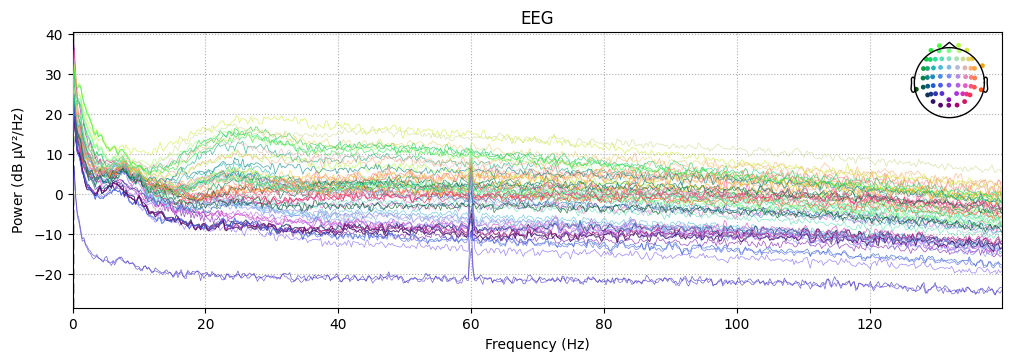


Subject: sub-002
Group: PD


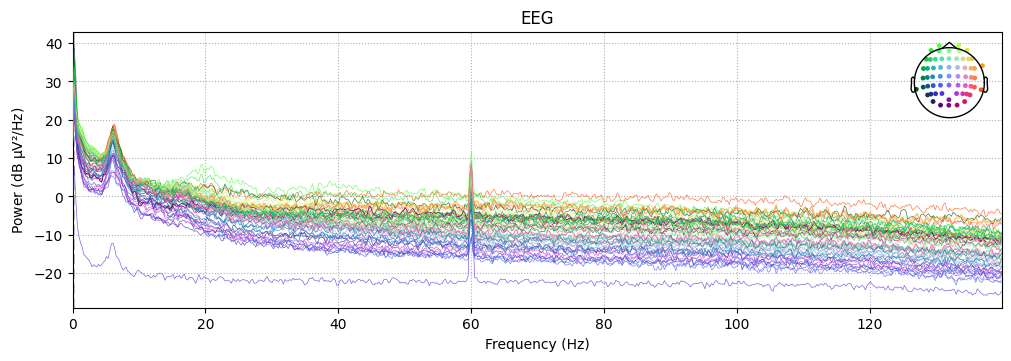


Subject: sub-101
Group: Control


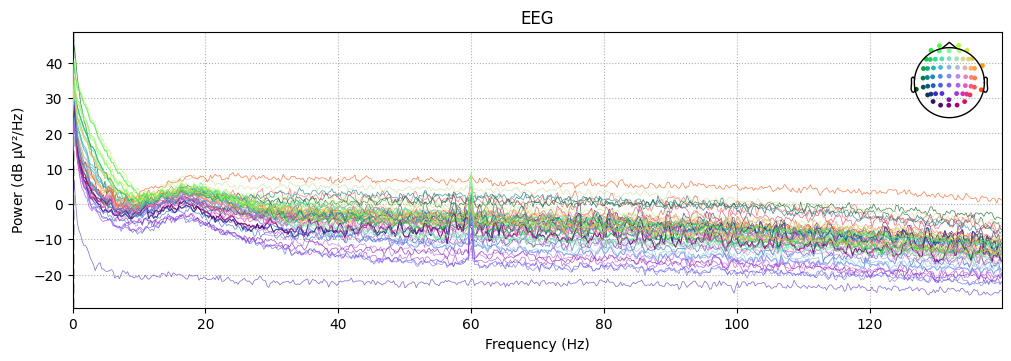


Subject: sub-102
Group: Control


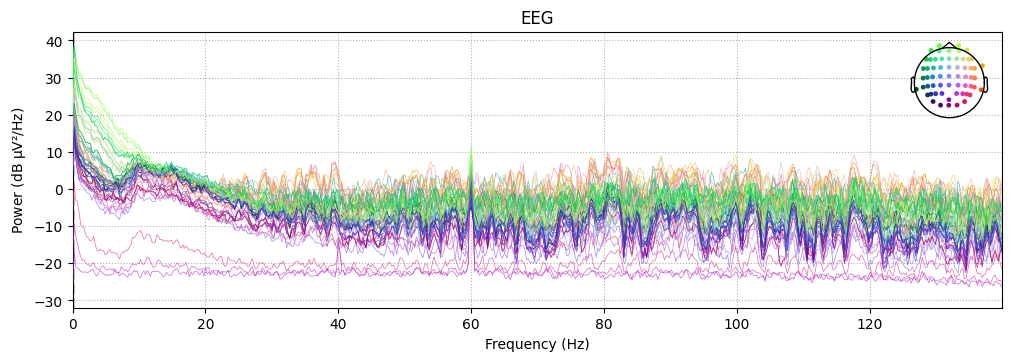

In [17]:
for subject_id in sample_subjects:
    raw = load_subject_standard(subject_id, inventory, COMMON_CHANNELS)

    montage = mne.channels.make_standard_montage("standard_1020")
    raw.set_montage(montage, on_missing="ignore")

    print(f"\nSubject: {subject_id}")
    print(
        f"Group: "
        f"{master_table.loc[master_table['subject_id'] == subject_id, 'GROUP'].values[0]}"
    )

    raw.compute_psd(fmax=140).plot(show=False)
    plt.show()

## 1. Preprocessing
### 1.1 Filtering

In [18]:
def filter_raw_eeg(raw, l_freq=1.0, h_freq=40.0):
    raw_filt = raw.copy()

    # Set standard electrode positions
    montage = mne.channels.make_standard_montage("standard_1020")
    raw_filt.set_montage(montage, on_missing="ignore")

    # Apply band-pass filter
    raw_filt.filter(l_freq=l_freq, h_freq=h_freq, verbose=False)

    return raw_filt

In [19]:
subject_id = "sub-001"

raw_before = load_subject_standard(subject_id, inventory, COMMON_CHANNELS)
raw_after = filter_raw_eeg(raw_before)

print(raw_before)
print(raw_after)

<RawEEGLAB | sub-001_task-Rest_eeg.fdt, 60 x 140830 (281.7 s), ~64.6 MB, data loaded>
<RawEEGLAB | sub-001_task-Rest_eeg.fdt, 60 x 140830 (281.7 s), ~64.6 MB, data loaded>


Before filtering


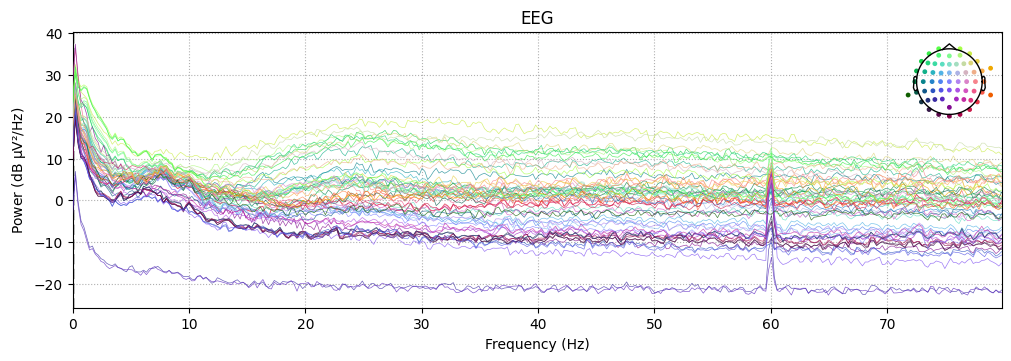

After filtering


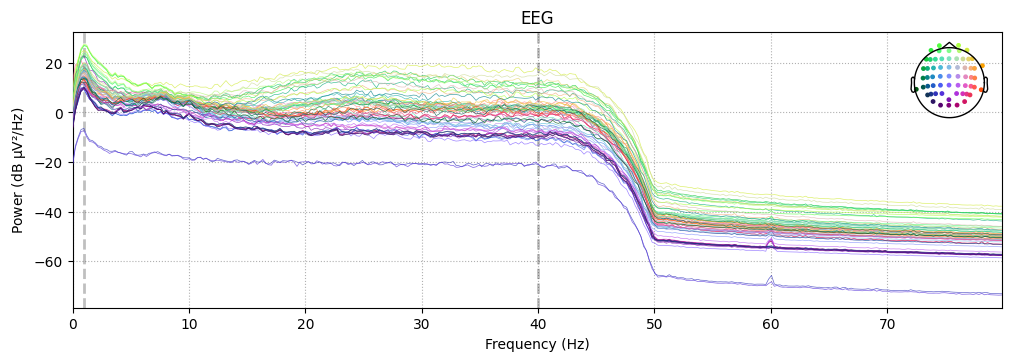

In [20]:
print("Before filtering")
raw_before.compute_psd(fmax=80).plot(show=False)
plt.show()

print("After filtering")
raw_after.compute_psd(fmax=80).plot(show=False)
plt.show()

### 1.2 Re-referencing

In [21]:
def rereference_raw_eeg(raw):
    raw_ref = raw.copy()
    raw_ref.set_eeg_reference("average", verbose=False)
    return raw_ref

In [22]:
subject_id = "sub-001"

raw_before = load_subject_standard(subject_id, inventory, COMMON_CHANNELS)
raw_filt = filter_raw_eeg(raw_before)
raw_ref = rereference_raw_eeg(raw_filt)

print(raw_ref)

<RawEEGLAB | sub-001_task-Rest_eeg.fdt, 60 x 140830 (281.7 s), ~64.6 MB, data loaded>


### 1.3 ICA-based artifact removal

In [39]:
from mne.preprocessing import ICA

def fit_ica(raw, n_components=20, random_state=42, max_iter="auto"):
    ica = ICA(
        n_components=n_components,
        random_state=random_state,
        max_iter=max_iter
    )
    
    ica.fit(raw, verbose=False)
    return ica

In [40]:
subject_id = "sub-001"

raw_before = load_subject_standard(subject_id, inventory, COMMON_CHANNELS)
raw_filt = filter_raw_eeg(raw_before)
raw_ref = rereference_raw_eeg(raw_filt)

ica = fit_ica(raw_ref)

ica

Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,54 iterations on raw data (140830 samples)
ICA components,20
Available PCA components,60
Channel types,eeg
ICA components marked for exclusion,—


In [22]:
%matplotlib widget

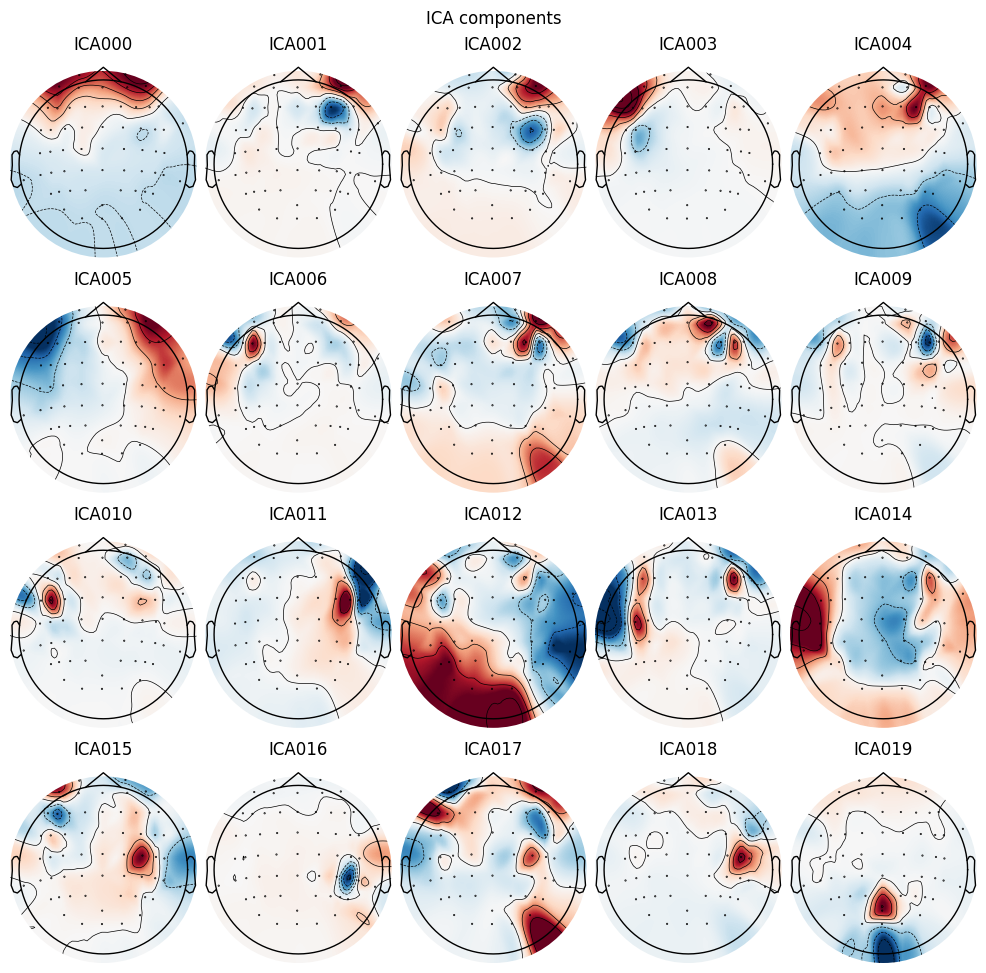

In [41]:
ica.plot_components();

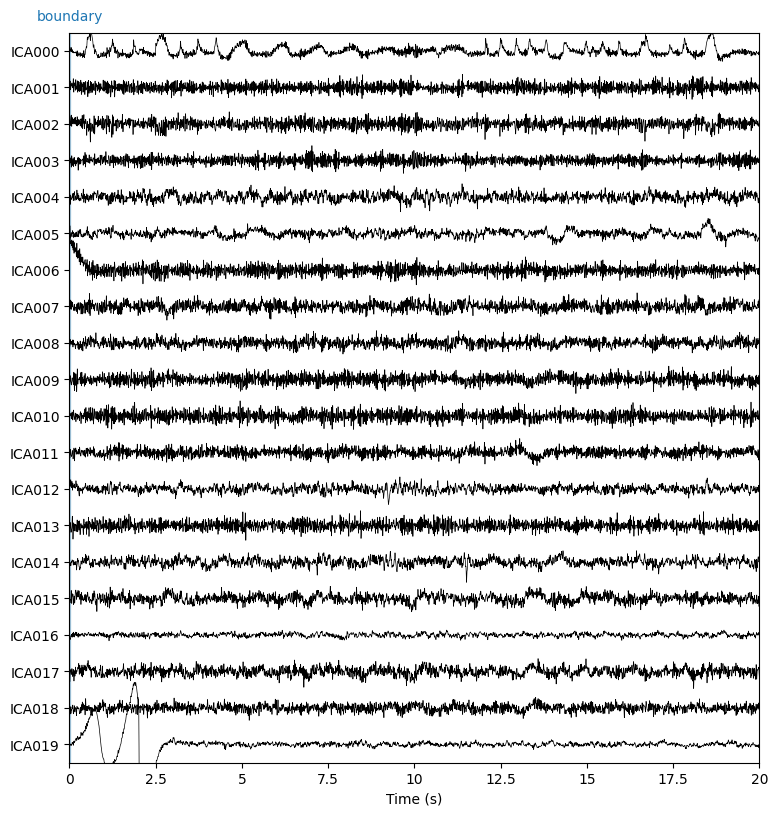

In [42]:
ica.plot_sources(raw_ref, show_scrollbars=False);

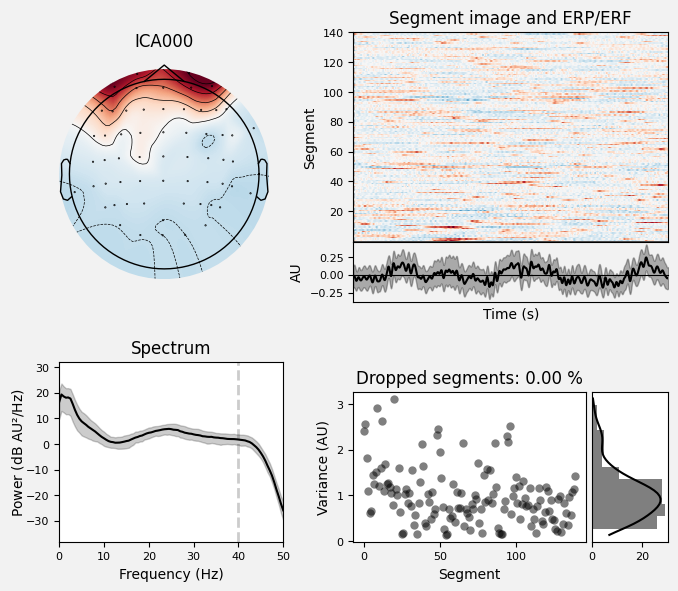

In [43]:
ica.plot_properties(raw_ref, picks=[0]);

In [44]:
ica.exclude = [0]
raw_ica = raw_ref.copy()
ica.apply(raw_ica)

<RawEEGLAB | sub-001_task-Rest_eeg.fdt, 60 x 140830 (281.7 s), ~64.6 MB, data loaded>

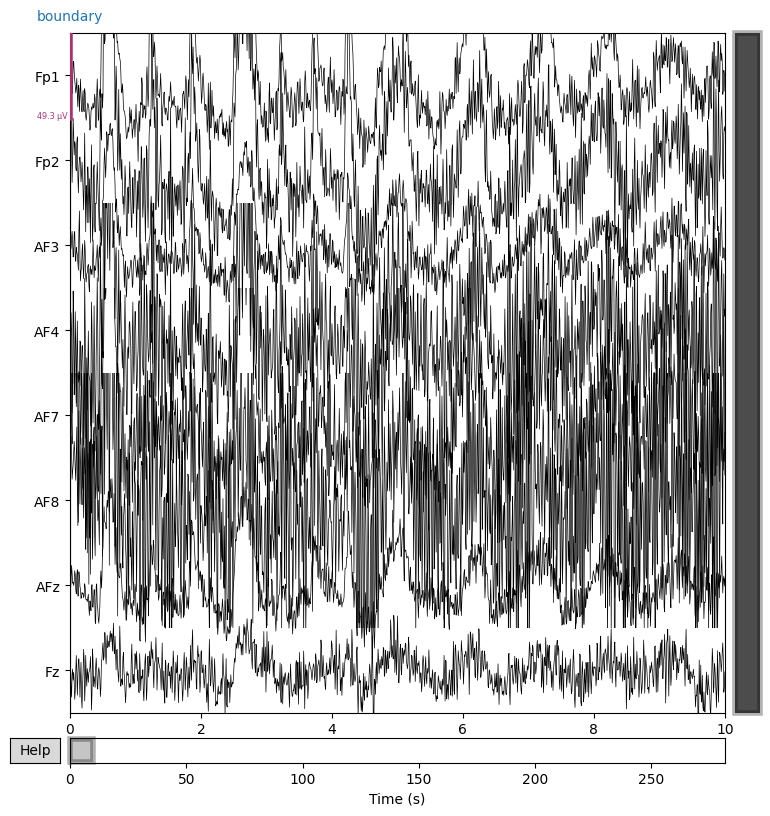

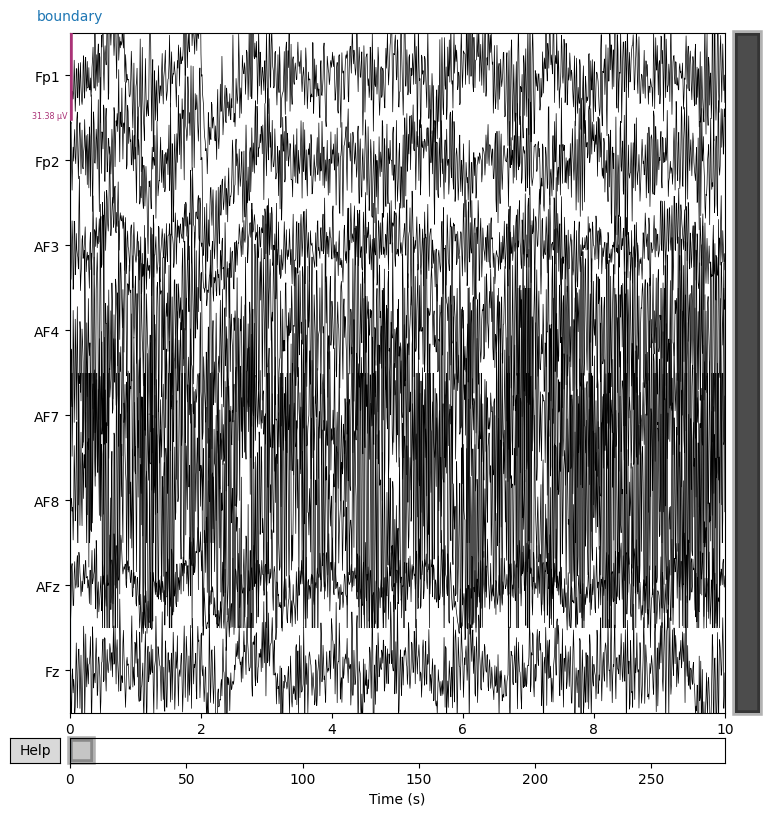

In [45]:
def plot_frontal_segment(raw, subject_id="unknown", start=0, duration=10):
    frontal_channels = ["Fp1", "Fp2", "AF3", "AF4", "AF7", "AF8", "AFz", "Fz"]

    available_channels = [ch for ch in frontal_channels if ch in raw.ch_names]

    raw.copy().pick(available_channels).plot(
        start=start,
        duration=duration,
        scalings="auto",
        n_channels=len(available_channels),
        title=f"{subject_id} | Frontal channels"
    )

plot_frontal_segment(raw_ref, subject_id="sub-001 before ICA", start=0, duration=10)
plot_frontal_segment(raw_ica, subject_id="sub-001 after ICA", start=0, duration=10)

Visual inspection suggested that ICA component 000 was associated with ocular blink activity due to its frontal topography and slow, repeated transient pattern. After excluding this component, frontal channels showed reduced blink-related activity.

In [33]:
def apply_ica_blink_removal(raw, n_components=20, exclude_components=[0], random_state=42):
    raw_ica = raw.copy()

    ica = ICA(
        n_components=n_components,
        random_state=random_state,
        max_iter="auto"
    )

    ica.fit(raw_ica, verbose=False)
    ica.exclude = exclude_components
    ica.apply(raw_ica)

    return raw_ica, ica

In [23]:
from pathlib import Path
import pandas as pd
from mne.preprocessing import ICA

ICA_LOG_PATH = Path("ica_component_selection.csv")

if ICA_LOG_PATH.exists():
    ica_log = pd.read_csv(ICA_LOG_PATH)
    reviewed_subjects = set(ica_log["subject_id"].tolist())
    ica_selection = {
        row["subject_id"]: [] if pd.isna(row["excluded_components"]) or row["excluded_components"] == "" 
        else [int(x.strip()) for x in str(row["excluded_components"]).split(",")]
        for _, row in ica_log.iterrows()
    }
else:
    ica_log = pd.DataFrame(columns=["subject_id", "excluded_components", "n_excluded"])
    reviewed_subjects = set()
    ica_selection = {}

In [38]:
def prepare_subject_for_ica(subject_id, inventory_df, common_channels):
    raw = load_subject_standard(subject_id, inventory_df, common_channels)
    raw = filter_raw_eeg(raw)
    raw = rereference_raw_eeg(raw)
    return raw

Reviewing subject: sub-149


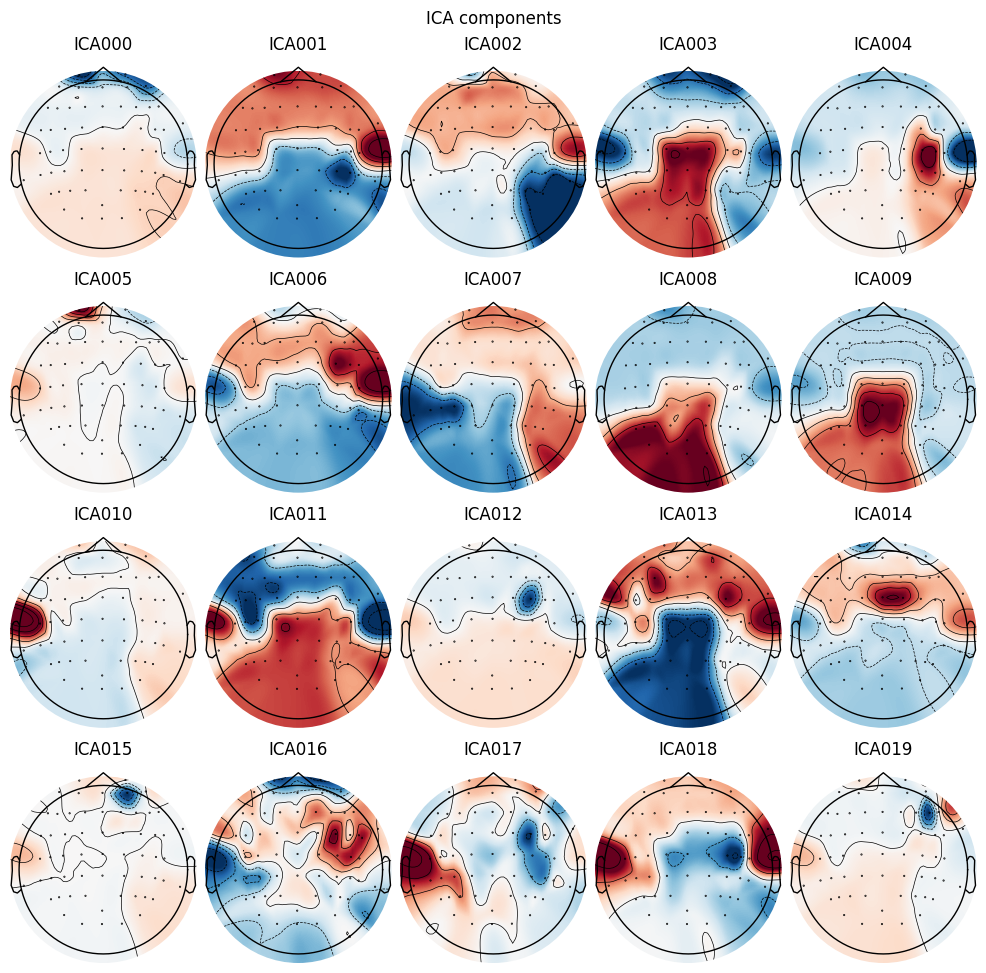

In [505]:
%matplotlib inline
from mne.preprocessing import ICA

subjects = master_table["subject_id"].tolist()

if "ica_selection" not in globals():
    ica_selection = {}

subject_id = "sub-149"
# Example alternatives:
# subject_id = subjects[0]
# subject_id = subjects[1]

raw = prepare_subject_for_ica(subject_id, inventory, COMMON_CHANNELS)

ica = ICA(
    n_components=20,
    random_state=42,
    max_iter="auto"
)
ica.fit(raw, verbose=False)

print(f"Reviewing subject: {subject_id}")
ica.plot_components();

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
64 matching events found
No baseline correction applied
0 projection items activated


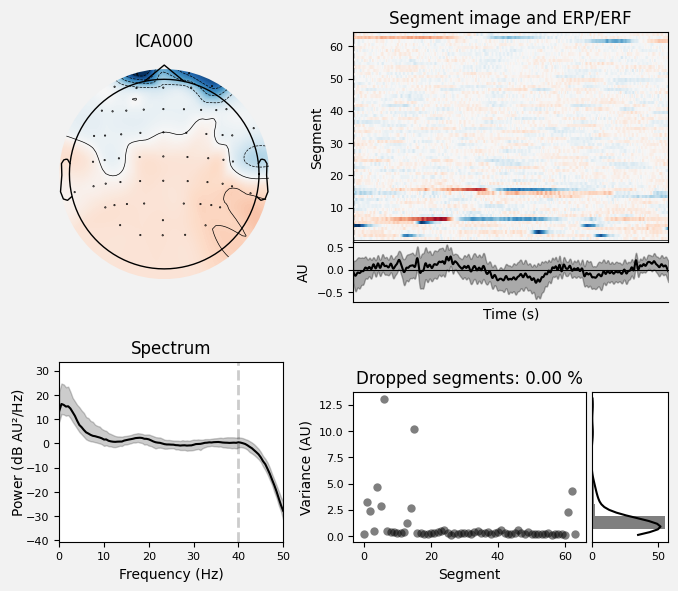

[<Figure size 700x600 with 6 Axes>]

In [506]:
ica.plot_properties(raw, picks=[0])
#ica.plot_properties(raw, picks=[2])
#ica.plot_properties(raw, picks=[2])

In [ ]:
#ica_selection[subject_id] = []   # change manually
#print(subject_id, ica_selection[subject_id])

sub-149 []


In [508]:
ica_selection

{'sub-001': [0],
 'sub-002': [],
 'sub-003': [],
 'sub-004': [0],
 'sub-005': [0],
 'sub-006': [],
 'sub-007': [0],
 'sub-008': [0],
 'sub-009': [1],
 'sub-010': [],
 'sub-011': [0],
 'sub-012': [0],
 'sub-013': [0],
 'sub-014': [0],
 'sub-015': [],
 'sub-016': [],
 'sub-017': [],
 'sub-018': [],
 'sub-019': [],
 'sub-020': [0],
 'sub-021': [0],
 'sub-022': [],
 'sub-023': [0],
 'sub-024': [],
 'sub-025': [],
 'sub-026': [],
 'sub-027': [],
 'sub-028': [1],
 'sub-029': [0],
 'sub-030': [],
 'sub-031': [],
 'sub-032': [],
 'sub-033': [0],
 'sub-034': [0],
 'sub-035': [0],
 'sub-036': [],
 'sub-037': [],
 'sub-038': [],
 'sub-039': [],
 'sub-040': [],
 'sub-041': [],
 'sub-042': [0],
 'sub-043': [],
 'sub-044': [],
 'sub-045': [1],
 'sub-046': [],
 'sub-047': [0],
 'sub-048': [],
 'sub-049': [],
 'sub-050': [],
 'sub-051': [0],
 'sub-052': [],
 'sub-053': [],
 'sub-054': [],
 'sub-055': [],
 'sub-056': [],
 'sub-057': [],
 'sub-058': [],
 'sub-059': [1],
 'sub-060': [],
 'sub-061': [],
 

In [509]:
ica_log = pd.DataFrame({
    "subject_id": list(ica_selection.keys()),
    "excluded_components": [str(v) for v in ica_selection.values()],
    "n_excluded": [len(v) for v in ica_selection.values()]
}).sort_values("subject_id")

ica_log.to_csv("ica_component_selection.csv", index=False)
ica_log.head()

,subject_id,excluded_components,n_excluded
0,sub-001,[0],1
1,sub-002,[],0
2,sub-003,[],0
3,sub-004,[0],1
4,sub-005,[0],1


In [510]:
ica_log["n_excluded"].value_counts(dropna=False)

n_excluded
0    103
1     46
Name: count, dtype: int64

In [26]:
ica_selection_dict = {
    row["subject_id"]: [] if row["excluded_components"] == "[]" else eval(row["excluded_components"])
    for _, row in ica_log.iterrows()
}

In [27]:
from mne.preprocessing import ICA

def clean_subject_with_saved_ica(subject_id, inventory_df, common_channels, ica_dict,
                                 l_freq=1.0, h_freq=40.0,
                                 n_components=20, random_state=42):
    # Load subject
    raw = load_subject_standard(subject_id, inventory_df, common_channels)

    # Filtering
    raw = filter_raw_eeg(raw, l_freq=l_freq, h_freq=h_freq)

    # Re-reference
    raw = rereference_raw_eeg(raw)

    # Fit ICA
    ica = ICA(
        n_components=n_components,
        random_state=random_state,
        max_iter="auto"
    )
    ica.fit(raw, verbose=False)

    # Apply saved exclusions
    exclude_components = ica_dict.get(subject_id, [])
    ica.exclude = exclude_components

    raw_clean = raw.copy()
    ica.apply(raw_clean)

    return raw_clean, ica, exclude_components

In [28]:
#raw original
subject_id = "sub-004"
raw_original = load_subject_standard(subject_id, inventory, COMMON_CHANNELS)

#raw preprocessed before ICA
raw_pre_ica = filter_raw_eeg(raw_original)
raw_pre_ica = rereference_raw_eeg(raw_pre_ica)

#raw after ICA cleaning
raw_clean, ica, excluded = clean_subject_with_saved_ica(
    subject_id,
    inventory,
    COMMON_CHANNELS,
    ica_selection_dict
)

In [529]:
%matplotlib widget

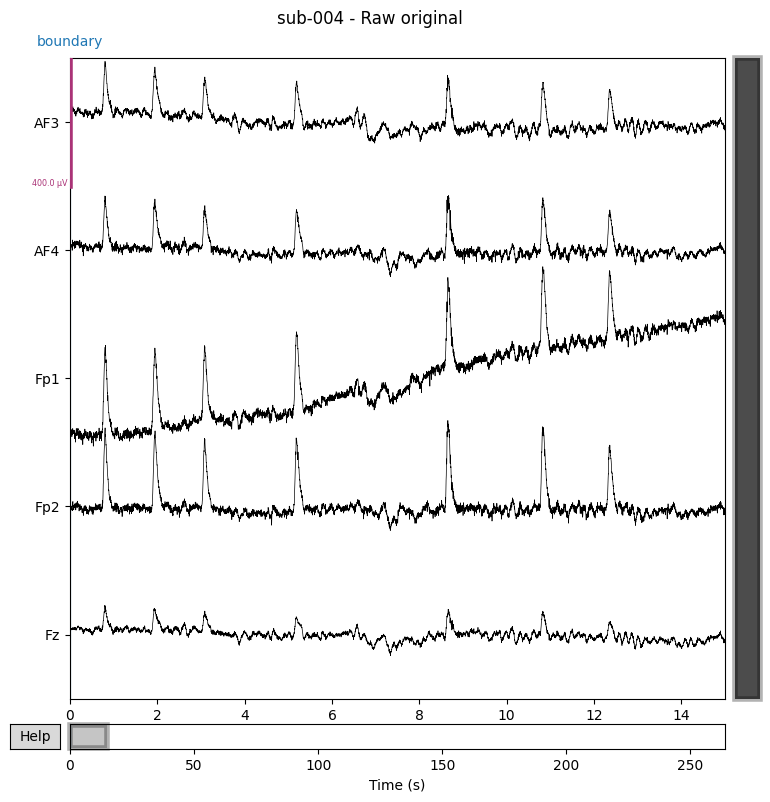

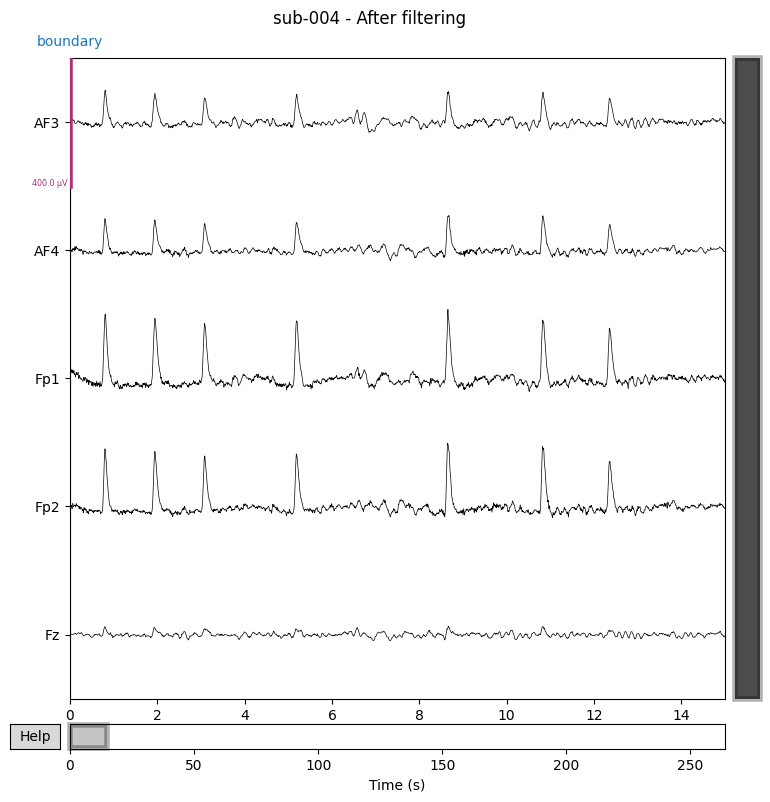

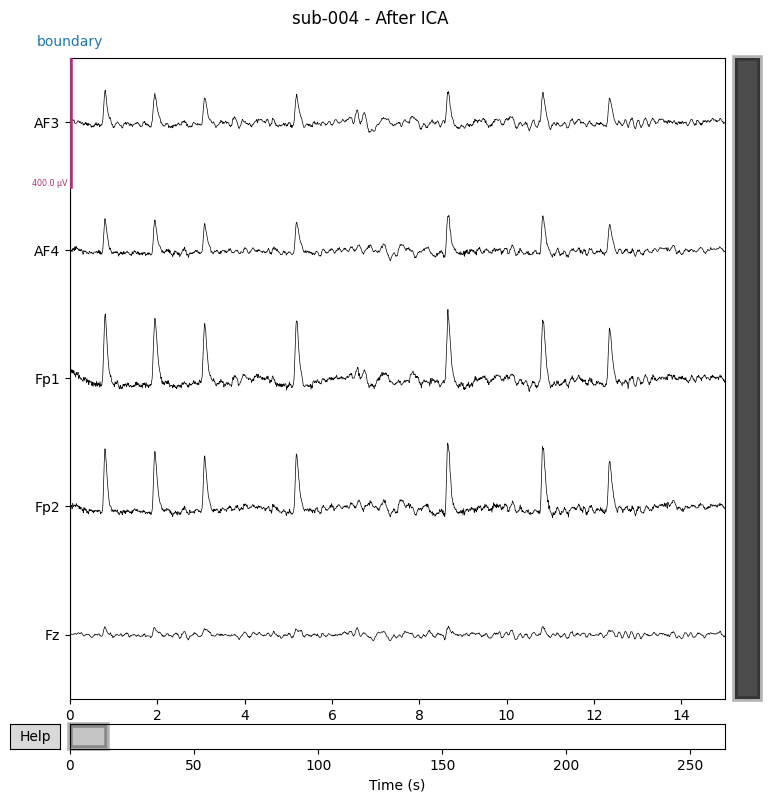

In [29]:
import matplotlib.pyplot as plt

# Channels focused on blink inspection
channels = ["Fp1", "Fp2", "AF3", "AF4", "Fz"]
available = [ch for ch in channels if ch in raw_original.ch_names]


# 1. Raw original
browser = raw_original.copy().plot(
    picks=available,
    scalings=dict(eeg=200e-6),
    start=0,
    duration=15,
    show=False
)
fig = plt.gcf()
fig.suptitle(f"{subject_id} - Raw original", fontsize=12)
fig.subplots_adjust(top=0.92)
fig.canvas.draw_idle()
plt.show()


# 2. After filtering
browser = raw_pre_ica.copy().plot(
    picks=available,
    scalings=dict(eeg=200e-6),
    start=0,
    duration=15,
    show=False
)
fig = plt.gcf()
fig.suptitle(f"{subject_id} - After filtering", fontsize=12)
fig.subplots_adjust(top=0.92)
fig.canvas.draw_idle()
plt.show()


# 3. After ICA
browser = raw_clean.copy().plot(
    picks=available,
    scalings=dict(eeg=200e-6),
    start=0,
    duration=15,
    show=False
)
fig = plt.gcf()
fig.suptitle(f"{subject_id} - After ICA", fontsize=12)
fig.subplots_adjust(top=0.92)
fig.canvas.draw_idle()
plt.show()

### 1.4 Epoching

In [30]:
def make_fixed_length_epochs(raw, duration=2.0, overlap=0.0):
    epochs = mne.make_fixed_length_epochs(
        raw,
        duration=duration,
        overlap=overlap,
        preload=True,
        reject_by_annotation=True,
        verbose=False
    )
    return epochs

In [31]:
epochs_004 = make_fixed_length_epochs(raw_clean, duration=2.0, overlap=0.0) #raw clean is subjett_id = "sub-004"

print(subject_id)
print("Excluded ICA components:", excluded)
print(epochs_004)
print("Number of epochs:", len(epochs_004))

sub-004
Excluded ICA components: []
<Epochs | 131 events (all good), 0 – 1.998 s (baseline off), ~60.1 MB, data loaded,
 '1': 131>
Number of epochs: 131


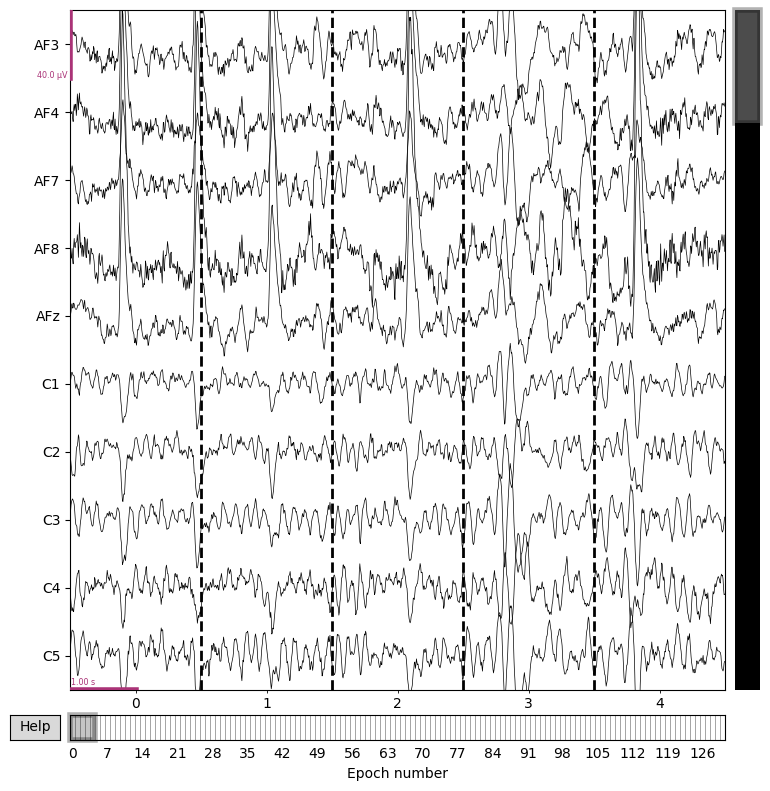

In [32]:
epochs_004.plot(n_epochs=5, n_channels=10);

In [560]:
print("Number of epochs:", len(epochs_004))
print(epochs_004.get_data().shape)

Number of epochs: 131
(131, 60, 1000)


## 2. Feature Extraction

In [561]:
import numpy as np
import pandas as pd
from scipy.signal import welch
from mne.preprocessing import ICA

def compute_bandpower(signal, sfreq, band, nperseg=None):
    low, high = band

    if nperseg is None:
        nperseg = min(len(signal), int(2 * sfreq))

    freqs, psd = welch(signal, fs=sfreq, nperseg=nperseg)
    freq_mask = (freqs >= low) & (freqs < high)

    if not np.any(freq_mask):
        return 0.0

    return np.trapz(psd[freq_mask], freqs[freq_mask])


def extract_features_from_epoch(epoch_data, sfreq, channel_names):
    bands = {
        "delta": (1, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "beta": (13, 30)
    }

    features = {}
    abs_bandpowers = {}

    for ch_idx, ch_name in enumerate(channel_names):
        signal = epoch_data[ch_idx]

        features[f"{ch_name}_mean"] = np.mean(signal)
        features[f"{ch_name}_std"] = np.std(signal)
        features[f"{ch_name}_rms"] = np.sqrt(np.mean(signal ** 2))
        features[f"{ch_name}_ptp"] = np.ptp(signal)

        abs_bandpowers[ch_name] = {}
        for band_name, band_range in bands.items():
            bp = compute_bandpower(signal, sfreq, band_range)
            abs_bandpowers[ch_name][band_name] = bp
            features[f"{ch_name}_{band_name}_abs_power"] = bp

    for ch_name in channel_names:
        channel_total = sum(abs_bandpowers[ch_name].values())

        for band_name in bands.keys():
            rel_power = abs_bandpowers[ch_name][band_name] / channel_total if channel_total > 0 else 0.0
            features[f"{ch_name}_{band_name}_rel_power"] = rel_power

        theta = abs_bandpowers[ch_name]["theta"]
        alpha = abs_bandpowers[ch_name]["alpha"]
        beta = abs_bandpowers[ch_name]["beta"]

        features[f"{ch_name}_alpha_theta_ratio"] = alpha / theta if theta > 0 else 0.0
        features[f"{ch_name}_theta_beta_ratio"] = theta / beta if beta > 0 else 0.0

    return features


def process_subject_to_features(subject_id, inventory_df, master_table_df, common_channels, ica_dict,
                                epoch_duration=2.0, epoch_overlap=0.0,
                                l_freq=1.0, h_freq=40.0,
                                n_components=20, random_state=42):
    raw = load_subject_standard(subject_id, inventory_df, common_channels)
    raw = filter_raw_eeg(raw, l_freq=l_freq, h_freq=h_freq)
    raw = rereference_raw_eeg(raw)

    ica = ICA(
        n_components=n_components,
        random_state=random_state,
        max_iter="auto"
    )
    ica.fit(raw, verbose=False)

    ica.exclude = ica_dict.get(subject_id, [])

    raw_clean = raw.copy()
    ica.apply(raw_clean)

    epochs = mne.make_fixed_length_epochs(
        raw_clean,
        duration=epoch_duration,
        overlap=epoch_overlap,
        preload=True,
        reject_by_annotation=True,
        verbose=False
    )

    epoch_data = epochs.get_data()
    sfreq = epochs.info["sfreq"]
    channel_names = epochs.ch_names

    group_value = master_table_df.loc[master_table_df["subject_id"] == subject_id, "GROUP"].values[0]
    target_value = master_table_df.loc[master_table_df["subject_id"] == subject_id, "target"].values[0]

    features_list = []

    for epoch_idx in range(len(epoch_data)):
        epoch_features = extract_features_from_epoch(epoch_data[epoch_idx], sfreq, channel_names)
        epoch_features["subject_id"] = subject_id
        epoch_features["epoch_idx"] = epoch_idx
        epoch_features["GROUP"] = group_value
        epoch_features["target"] = target_value
        features_list.append(epoch_features)

    return pd.DataFrame(features_list)

In [562]:
features_df_004 = process_subject_to_features(
    subject_id="sub-004",
    inventory_df=inventory,
    master_table_df=master_table,
    common_channels=COMMON_CHANNELS,
    ica_dict=ica_selection_dict
)

print(features_df_004.shape)
features_df_004.head()

Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
(131, 844)


,AF3_mean,AF3_std,AF3_rms,AF3_ptp,AF3_delta_abs_power,AF3_theta_abs_power,AF3_alpha_abs_power,AF3_beta_abs_power,AF4_mean,AF4_std,...,TP9_delta_rel_power,TP9_theta_rel_power,TP9_alpha_rel_power,TP9_beta_rel_power,TP9_alpha_theta_ratio,TP9_theta_beta_ratio,subject_id,epoch_idx,GROUP,target
0,1.988772e-07,0.000005,0.000005,0.000025,3.121238e-12,1.443061e-11,1.688587e-12,3.368612e-12,-4.537642e-07,0.000004,...,0.162273,0.473024,0.131215,0.233488,0.277397,2.025903,sub-004,0,PD,1
1,-5.444102e-10,0.000006,0.000006,0.000039,1.310103e-11,5.925654e-12,2.112675e-12,2.213761e-12,4.417110e-07,0.000005,...,0.223261,0.592888,0.084133,0.099717,0.141904,5.945698,sub-004,1,PD,1
2,-4.200817e-07,0.000006,0.000006,0.000030,5.068960e-12,9.319425e-12,2.767972e-12,2.506777e-12,1.661540e-07,0.000006,...,0.376567,0.369283,0.123802,0.130348,0.335251,2.833059,sub-004,2,PD,1
3,8.206256e-07,0.000013,0.000013,0.000069,1.663732e-10,4.912674e-11,2.493322e-12,1.430515e-12,-7.476305e-07,0.000009,...,0.549758,0.402143,0.023810,0.024289,0.059207,16.556281,sub-004,3,PD,1
4,-6.072494e-07,0.000008,0.000008,0.000035,1.892134e-11,5.040741e-12,2.703119e-12,4.038930e-12,6.767935e-07,0.000007,...,0.209261,0.674372,0.034127,0.082240,0.050606,8.200002,sub-004,4,PD,1


In [563]:
subject_list = master_table["subject_id"].tolist()
chunk_size = 20

for start in range(0, len(subject_list), chunk_size):
    end = min(start + chunk_size, len(subject_list))
    chunk_subjects = subject_list[start:end]
    all_features = []

    print(f"Processing subjects {start} to {end-1}")

    for subject_id in chunk_subjects:
        print(f"  {subject_id}")
        subject_features = process_subject_to_features(
            subject_id=subject_id,
            inventory_df=inventory,
            master_table_df=master_table,
            common_channels=COMMON_CHANNELS,
            ica_dict=ica_selection_dict
        )
        all_features.append(subject_features)

    chunk_df = pd.concat(all_features, ignore_index=True)
    chunk_df.to_csv(f"eeg_features_chunk_{start}_{end-1}.csv", index=False)

Processing subjects 0 to 19
  sub-001
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-002
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-003
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-004
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-005
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-006
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  s

/var/folders/gh/44dqhlxj0dl4ghy8z0wc2sy00000gn/T/ipykernel_91301/1951443976.py:76: RuntimeWarning: Using n_components=20 (resulting in n_components_=20) may lead to an unstable mixing matrix estimation because the ratio between the largest (60) and smallest (1.4e-05) variances is too large (> 1e6); consider setting n_components=0.999999 or an integer <= 10
  ica.fit(raw, verbose=False)


Processing subjects 40 to 59
  sub-041
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-042
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-043
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-044
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-045
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components


/Users/azucenaalvarez/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


  sub-046
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-047
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-048
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-049
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components


...

  sub-056
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-057
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-058
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-059
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-060
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
Processing subjects 60 to 79
  sub-061
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components


/Users/azucenaalvarez/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


  sub-122
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-123
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-124
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-125
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-126
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-127
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-128
Applying ICA to Raw i

/Users/azucenaalvarez/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


  sub-143
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-144
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-145
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-146
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-147
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components
  sub-148
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 60 PCA components
  sub-149
Applying ICA to Raw

In [564]:
from pathlib import Path
import pandas as pd

chunk_files = sorted(Path(".").glob("eeg_features_chunk_*.csv"))

print(f"Number of chunk files found: {len(chunk_files)}")
for f in chunk_files:
    print(f.name)

features_df = pd.concat([pd.read_csv(f) for f in chunk_files], ignore_index=True)

print(features_df.shape)
features_df.head()

Number of chunk files found: 8
eeg_features_chunk_0_19.csv
eeg_features_chunk_100_119.csv
eeg_features_chunk_120_139.csv
eeg_features_chunk_140_148.csv
eeg_features_chunk_20_39.csv
eeg_features_chunk_40_59.csv
eeg_features_chunk_60_79.csv
eeg_features_chunk_80_99.csv
(11878, 844)


,AF3_mean,AF3_std,AF3_rms,AF3_ptp,AF3_delta_abs_power,AF3_theta_abs_power,AF3_alpha_abs_power,AF3_beta_abs_power,AF4_mean,AF4_std,...,TP9_delta_rel_power,TP9_theta_rel_power,TP9_alpha_rel_power,TP9_beta_rel_power,TP9_alpha_theta_ratio,TP9_theta_beta_ratio,subject_id,epoch_idx,GROUP,target
0,1.945497e-06,0.000010,0.000010,0.000057,2.051662e-11,1.743583e-12,1.232300e-12,2.378399e-11,2.337527e-07,0.000021,...,0.270650,0.074981,0.209832,0.444537,2.798452,0.168673,sub-001,0,PD,1
1,-2.228159e-06,0.000009,0.000009,0.000051,1.246657e-11,1.912712e-12,2.697801e-12,1.731651e-11,-3.476335e-06,0.000021,...,0.668318,0.082787,0.047419,0.201475,0.572786,0.410904,sub-001,1,PD,1
2,1.360429e-08,0.000008,0.000008,0.000043,3.000034e-12,2.148021e-12,1.799326e-12,2.942893e-11,6.637829e-07,0.000018,...,0.324153,0.219694,0.105505,0.350649,0.480235,0.626535,sub-001,2,PD,1
3,2.619408e-07,0.000009,0.000009,0.000049,2.550475e-12,2.603998e-12,1.902546e-12,3.076122e-11,2.080256e-07,0.000018,...,0.050091,0.264845,0.174220,0.510844,0.657817,0.518447,sub-001,3,PD,1
4,-2.929143e-07,0.000008,0.000008,0.000047,5.110508e-12,2.767818e-12,3.244660e-12,2.945603e-11,6.660811e-08,0.000020,...,0.140999,0.233441,0.397772,0.227787,1.703949,1.024823,sub-001,4,PD,1


In [565]:
features_df.to_csv("eeg_features_dataset.csv", index=False)

print(features_df["GROUP"].value_counts(dropna=False))
print(features_df["target"].value_counts(dropna=False))
print(features_df[["subject_id", "epoch_idx"]].head())
print(features_df.isna().sum().sort_values(ascending=False).head(20))

GROUP
PD         7739
Control    4139
Name: count, dtype: int64
target
1    7739
0    4139
Name: count, dtype: int64
  subject_id  epoch_idx
0    sub-001          0
1    sub-001          1
2    sub-001          2
3    sub-001          3
4    sub-001          4
AF3_mean                 0
CP6_alpha_theta_ratio    0
CP2_alpha_theta_ratio    0
CP2_theta_beta_ratio     0
CP3_delta_rel_power      0
CP3_theta_rel_power      0
CP3_alpha_rel_power      0
CP3_beta_rel_power       0
CP3_alpha_theta_ratio    0
CP3_theta_beta_ratio     0
CP4_delta_rel_power      0
CP4_theta_rel_power      0
CP4_alpha_rel_power      0
CP4_beta_rel_power       0
CP4_alpha_theta_ratio    0
CP4_theta_beta_ratio     0
CP5_delta_rel_power      0
CP5_theta_rel_power      0
CP5_alpha_rel_power      0
CP5_beta_rel_power       0
dtype: int64


In [566]:
features_df.shape

(11878, 844)

In [33]:
features_df = pd.read_csv("eeg_features_dataset.csv")

print(features_df.shape)
print(features_df[["subject_id", "epoch_idx", "GROUP", "target"]].head())

(11878, 844)
  subject_id  epoch_idx GROUP  target
0    sub-001          0    PD       1
1    sub-001          1    PD       1
2    sub-001          2    PD       1
3    sub-001          3    PD       1
4    sub-001          4    PD       1


In [34]:
# ICA QC flags
ica_warning_subjects = ["sub-045", "sub-049", "sub-054", "sub-055", "sub-121", "sub-142"]
ica_unstable_subjects = ["sub-040"]

ica_flagged_subjects = sorted(ica_warning_subjects + ica_unstable_subjects)

features_df["ica_qc_flag"] = features_df["subject_id"].isin(ica_flagged_subjects).astype(int)

print(features_df["ica_qc_flag"].value_counts())
features_df[["subject_id", "ica_qc_flag"]].drop_duplicates().head(20)

ica_qc_flag
0    11419
1      459
Name: count, dtype: int64


,subject_id,ica_qc_flag
0,sub-001,0
140,sub-002,0
303,sub-003,0
429,sub-004,0
560,sub-005,0
684,sub-006,0
815,sub-007,0
934,sub-008,0
1051,sub-009,0
1175,sub-010,0


## 3. Feature Selection

In [36]:
# Columns that should not be used as predictors
non_feature_cols = ["subject_id", "epoch_idx", "GROUP", "target"]

# Keep ICA QC flag as metadata for now, not as predictor
# You can include it later if you want to test its effect
non_feature_cols_with_qc = non_feature_cols + ["ica_qc_flag"]

feature_cols = [c for c in features_df.columns if c not in non_feature_cols_with_qc]

print("Number of feature columns:", len(feature_cols))
print(feature_cols[:20])

Number of feature columns: 840
['AF3_mean', 'AF3_std', 'AF3_rms', 'AF3_ptp', 'AF3_delta_abs_power', 'AF3_theta_abs_power', 'AF3_alpha_abs_power', 'AF3_beta_abs_power', 'AF4_mean', 'AF4_std', 'AF4_rms', 'AF4_ptp', 'AF4_delta_abs_power', 'AF4_theta_abs_power', 'AF4_alpha_abs_power', 'AF4_beta_abs_power', 'AF7_mean', 'AF7_std', 'AF7_rms', 'AF7_ptp']


In [37]:
from sklearn.model_selection import train_test_split

# Subject-level table
subject_table = features_df[["subject_id", "GROUP", "target", "ica_qc_flag"]].drop_duplicates()

# Split subjects, not epochs
train_subjects, test_subjects = train_test_split(
    subject_table["subject_id"],
    test_size=0.2,
    random_state=42,
    stratify=subject_table["target"]
)

print("Train subjects:", len(train_subjects))
print("Test subjects:", len(test_subjects))

Train subjects: 119
Test subjects: 30


In [38]:
train_df = features_df[features_df["subject_id"].isin(train_subjects)].copy()
test_df = features_df[features_df["subject_id"].isin(test_subjects)].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain target distribution:")
print(train_df["target"].value_counts())

print("\nTest target distribution:")
print(test_df["target"].value_counts())

Train shape: (9295, 845)
Test shape: (2583, 845)

Train target distribution:
target
1    6042
0    3253
Name: count, dtype: int64

Test target distribution:
target
1    1697
0     886
Name: count, dtype: int64


In [39]:
X_train = train_df[feature_cols].copy()
y_train = train_df["target"].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df["target"].copy()

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(9295, 840) (9295,)
(2583, 840) (2583,)


In [40]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

mi_df = pd.DataFrame({
    "feature": X_train.columns,
    "mi_score": mi_scores
}).sort_values("mi_score", ascending=False)

mi_df.head(30)

,feature,mi_score
769,P6_theta_rel_power,0.065537
571,CP5_theta_rel_power,0.063365
757,P4_theta_rel_power,0.062196
745,P2_theta_rel_power,0.058735
269,FCz_theta_abs_power,0.058300
229,FC2_theta_abs_power,0.057310
125,CP5_theta_abs_power,0.057193
781,P8_theta_rel_power,0.056138
245,FC4_theta_abs_power,0.055558
751,P3_theta_rel_power,0.054999


In [41]:
TOP_K = 50

selected_features = mi_df["feature"].head(TOP_K).tolist()

print("Number of selected features:", len(selected_features))
print(selected_features[:20])

Number of selected features: 50
['P6_theta_rel_power', 'CP5_theta_rel_power', 'P4_theta_rel_power', 'P2_theta_rel_power', 'FCz_theta_abs_power', 'FC2_theta_abs_power', 'CP5_theta_abs_power', 'P8_theta_rel_power', 'FC4_theta_abs_power', 'P3_theta_rel_power', 'PO8_theta_abs_power', 'C5_theta_abs_power', 'FC1_theta_abs_power', 'P5_theta_rel_power', 'P4_theta_abs_power', 'P6_theta_abs_power', 'FC3_theta_abs_power', 'TP7_theta_rel_power', 'P7_theta_rel_power', 'P2_theta_beta_ratio']


In [42]:
X_train_sel = X_train[selected_features].copy()
X_test_sel = X_test[selected_features].copy()

print(X_train_sel.shape)
print(X_test_sel.shape)

(9295, 50)
(2583, 50)


In [43]:
mi_df.to_csv("mi_feature_ranking.csv", index=False)

pd.DataFrame({"selected_feature": selected_features}).to_csv(
    "mi_selected_features_top50.csv",
    index=False
)

In [44]:
mi_df.head(20)

,feature,mi_score
769,P6_theta_rel_power,0.065537
571,CP5_theta_rel_power,0.063365
757,P4_theta_rel_power,0.062196
745,P2_theta_rel_power,0.058735
269,FCz_theta_abs_power,0.058300
229,FC2_theta_abs_power,0.057310
125,CP5_theta_abs_power,0.057193
781,P8_theta_rel_power,0.056138
245,FC4_theta_abs_power,0.055558
751,P3_theta_rel_power,0.054999


In [45]:
TOP_K_50 = 50

mi_df_top50 = mi_df.copy()
selected_features_top50 = mi_df_top50["feature"].head(TOP_K_50).tolist()

X_train_sel_50 = X_train[selected_features_top50].copy()
X_test_sel_50 = X_test[selected_features_top50].copy()

pd.DataFrame({"selected_feature": selected_features_top50}).to_csv(
    "mi_selected_features_top50.csv",
    index=False
)

mi_df_top50.to_csv("mi_feature_ranking_top50_base.csv", index=False)

print(X_train_sel_50.shape)
print(X_test_sel_50.shape)
print(selected_features_top50[:20])

(9295, 50)
(2583, 50)
['P6_theta_rel_power', 'CP5_theta_rel_power', 'P4_theta_rel_power', 'P2_theta_rel_power', 'FCz_theta_abs_power', 'FC2_theta_abs_power', 'CP5_theta_abs_power', 'P8_theta_rel_power', 'FC4_theta_abs_power', 'P3_theta_rel_power', 'PO8_theta_abs_power', 'C5_theta_abs_power', 'FC1_theta_abs_power', 'P5_theta_rel_power', 'P4_theta_abs_power', 'P6_theta_abs_power', 'FC3_theta_abs_power', 'TP7_theta_rel_power', 'P7_theta_rel_power', 'P2_theta_beta_ratio']


In [578]:
def build_mi_topk_datasets(mi_ranking_df, X_train, X_test, top_k, prefix="mi"):
    selected_features = mi_ranking_df["feature"].head(top_k).tolist()

    X_train_sel = X_train[selected_features].copy()
    X_test_sel = X_test[selected_features].copy()

    pd.DataFrame({"selected_feature": selected_features}).to_csv(
        f"{prefix}_selected_features_top{top_k}.csv",
        index=False
    )

    return selected_features, X_train_sel, X_test_sel

In [579]:
selected_features_top20, X_train_sel_20, X_test_sel_20 = build_mi_topk_datasets(
    mi_ranking_df=mi_df,
    X_train=X_train,
    X_test=X_test,
    top_k=20,
    prefix="mi"
)

selected_features_top100, X_train_sel_100, X_test_sel_100 = build_mi_topk_datasets(
    mi_ranking_df=mi_df,
    X_train=X_train,
    X_test=X_test,
    top_k=100,
    prefix="mi"
)

print("Top 20:", X_train_sel_20.shape, X_test_sel_20.shape)
print("Top 100:", X_train_sel_100.shape, X_test_sel_100.shape)

Top 20: (9295, 20) (2583, 20)
Top 100: (9295, 100) (2583, 100)


## 4. Data Preparation

In [46]:
from sklearn.preprocessing import StandardScaler

scaler_50 = StandardScaler()

X_train_sel_50_scaled = scaler_50.fit_transform(X_train_sel_50)
X_test_sel_50_scaled = scaler_50.transform(X_test_sel_50)

print(X_train_sel_50_scaled.shape)
print(X_test_sel_50_scaled.shape)

(9295, 50)
(2583, 50)


In [581]:
scaler_20 = StandardScaler()
X_train_sel_20_scaled = scaler_20.fit_transform(X_train_sel_20)
X_test_sel_20_scaled = scaler_20.transform(X_test_sel_20)

scaler_100 = StandardScaler()
X_train_sel_100_scaled = scaler_100.fit_transform(X_train_sel_100)
X_test_sel_100_scaled = scaler_100.transform(X_test_sel_100)

print("Top 20:", X_train_sel_20_scaled.shape, X_test_sel_20_scaled.shape)
print("Top 100:", X_train_sel_100_scaled.shape, X_test_sel_100_scaled.shape)

Top 20: (9295, 20) (2583, 20)
Top 100: (9295, 100) (2583, 100)


In [582]:
print("Train target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Train target distribution:
target
1    0.650027
0    0.349973
Name: proportion, dtype: float64

Test target distribution:
target
1    0.656988
0    0.343012
Name: proportion, dtype: float64


The class distribution was moderately imbalanced but remained consistent between training and test sets after subject-level stratified splitting. Therefore, no additional resampling strategy was applied at this stage, and class weighting was considered during model training when appropriate.

## 5. Model Training and Classification

In [47]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [48]:
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

In [49]:
trained_models = {}
model_predictions = {}
model_probabilities = {}
model_metrics = []

for model_name, model in models.items():
    print(f"Training {model_name}...")

    model.fit(X_train_sel_50_scaled, y_train)

    y_pred = model.predict(X_test_sel_50_scaled)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_sel_50_scaled)[:, 1]
    else:
        y_proba = None

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    trained_models[model_name] = model
    model_predictions[model_name] = y_pred
    model_probabilities[model_name] = y_proba

    model_metrics.append({
        "model": model_name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1
    })

metrics_df = pd.DataFrame(model_metrics).sort_values("f1_score", ascending=False)
metrics_df

Training LogisticRegression...
Training SVM...
Training RandomForest...


,model,accuracy,precision,recall,f1_score
2,RandomForest,0.735966,0.762003,0.869770,0.812328
0,LogisticRegression,0.662021,0.872514,0.568651,0.688548
1,SVM,0.608595,0.946615,0.428403,0.589858


In [50]:
metrics_df.to_csv("model_metrics_top50.csv", index=False)

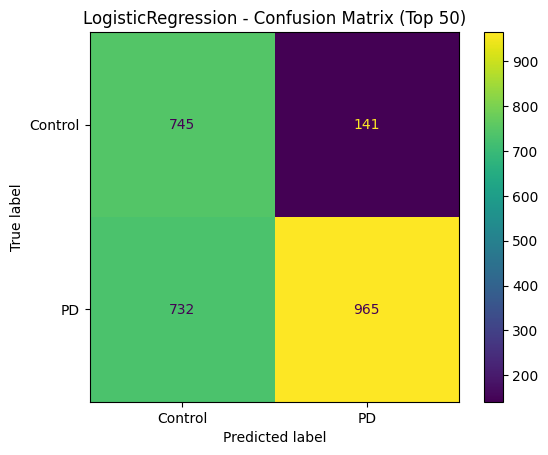

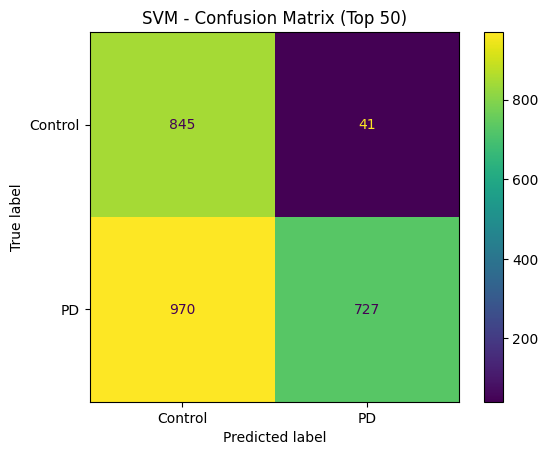

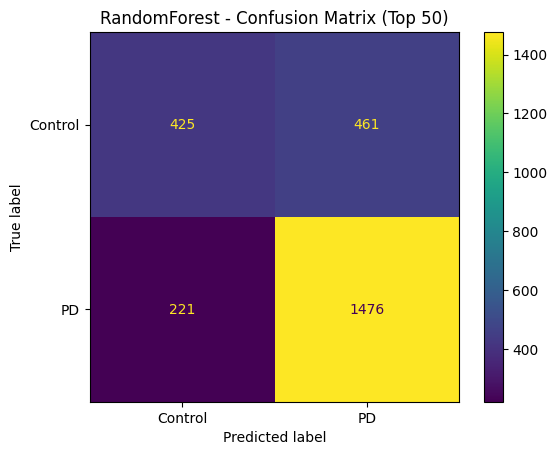

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for model_name, y_pred in model_predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Control", "PD"])
    disp.plot()
    plt.title(f"{model_name} - Confusion Matrix (Top 50)")
    plt.show()

In [52]:
for model_name, y_pred in model_predictions.items():
    print("=" * 60)
    print(model_name)
    print(classification_report(y_test, y_pred, target_names=["Control", "PD"], zero_division=0))

LogisticRegression
              precision    recall  f1-score   support

     Control       0.50      0.84      0.63       886
          PD       0.87      0.57      0.69      1697

    accuracy                           0.66      2583
   macro avg       0.69      0.70      0.66      2583
weighted avg       0.75      0.66      0.67      2583

SVM
              precision    recall  f1-score   support

     Control       0.47      0.95      0.63       886
          PD       0.95      0.43      0.59      1697

    accuracy                           0.61      2583
   macro avg       0.71      0.69      0.61      2583
weighted avg       0.78      0.61      0.60      2583

RandomForest
              precision    recall  f1-score   support

     Control       0.66      0.48      0.55       886
          PD       0.76      0.87      0.81      1697

    accuracy                           0.74      2583
   macro avg       0.71      0.67      0.68      2583
weighted avg       0.73      0.74     

In [53]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_cv = train_df[selected_features_top50].copy()
y_cv = train_df["target"].copy()
groups_cv = train_df["subject_id"].copy()

In [55]:
cv = GroupKFold(n_splits=5)

cv_models = {
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", class_weight="balanced", random_state=42))
    ]),
    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

In [56]:
cv_results = []

for model_name, model in cv_models.items():
    scores = cross_val_score(
        model,
        X_cv,
        y_cv,
        cv=cv,
        groups=groups_cv,
        scoring="f1",
        n_jobs=1
    )

    cv_results.append({
        "model": model_name,
        "cv_f1_mean": scores.mean(),
        "cv_f1_std": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("cv_f1_mean", ascending=False)
cv_results_df

,model,cv_f1_mean,cv_f1_std
2,RandomForest,0.751266,0.022848
0,LogisticRegression,0.650103,0.067728
1,SVM,0.594079,0.083985


In [57]:
from sklearn.neural_network import MLPClassifier

In [58]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=128,
    learning_rate_init=1e-3,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

mlp_model.fit(X_train_sel_50_scaled, y_train)

y_pred_mlp = mlp_model.predict(X_test_sel_50_scaled)
y_proba_mlp = mlp_model.predict_proba(X_test_sel_50_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_mlp))
print("Precision:", precision_score(y_test, y_pred_mlp, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_mlp, zero_division=0))
print("F1:", f1_score(y_test, y_pred_mlp, zero_division=0))
print(confusion_matrix(y_test, y_pred_mlp))

Accuracy: 0.686411149825784
Precision: 0.7874270900842515
Recall: 0.7159693576900412
F1: 0.75
[[ 558  328]
 [ 482 1215]]


In [59]:
mlp_metrics_row = pd.DataFrame([{
    "model": "MLP",
    "accuracy": accuracy_score(y_test, y_pred_mlp),
    "precision": precision_score(y_test, y_pred_mlp, zero_division=0),
    "recall": recall_score(y_test, y_pred_mlp, zero_division=0),
    "f1_score": f1_score(y_test, y_pred_mlp, zero_division=0)
}])

metrics_df_with_mlp = pd.concat([metrics_df, mlp_metrics_row], ignore_index=True).sort_values(
    "f1_score", ascending=False
)

metrics_df_with_mlp

,model,accuracy,precision,recall,f1_score
0,RandomForest,0.735966,0.762003,0.869770,0.812328
3,MLP,0.686411,0.787427,0.715969,0.750000
1,LogisticRegression,0.662021,0.872514,0.568651,0.688548
2,SVM,0.608595,0.946615,0.428403,0.589858


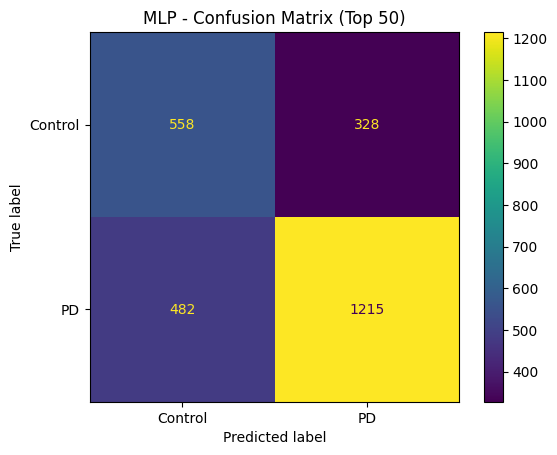

In [60]:
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=["Control", "PD"])
disp.plot()
plt.title("MLP - Confusion Matrix (Top 50)")
plt.show()

In [61]:
print(classification_report(y_test, y_pred_mlp, target_names=["Control", "PD"], zero_division=0))

              precision    recall  f1-score   support

     Control       0.54      0.63      0.58       886
          PD       0.79      0.72      0.75      1697

    accuracy                           0.69      2583
   macro avg       0.66      0.67      0.66      2583
weighted avg       0.70      0.69      0.69      2583



In [62]:
mlp_cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=128,
        learning_rate_init=1e-3,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=42
    ))
])

mlp_cv_scores = cross_val_score(
    mlp_cv_model,
    X_cv,
    y_cv,
    cv=cv,
    groups=groups_cv,
    scoring="f1",
    n_jobs=1
)

print("MLP CV F1 mean:", mlp_cv_scores.mean())
print("MLP CV F1 std:", mlp_cv_scores.std())
print("Fold scores:", mlp_cv_scores)

MLP CV F1 mean: 0.7123023170505547
MLP CV F1 std: 0.04354794967871283
Fold scores: [0.74398422 0.7358263  0.627051   0.7171799  0.73747017]


In [63]:
mlp_cv_row = pd.DataFrame([{
    "model": "MLP",
    "cv_f1_mean": mlp_cv_scores.mean(),
    "cv_f1_std": mlp_cv_scores.std()
}])

cv_results_with_mlp = pd.concat([cv_results_df, mlp_cv_row], ignore_index=True).sort_values(
    "cv_f1_mean", ascending=False
)

cv_results_with_mlp

,model,cv_f1_mean,cv_f1_std
0,RandomForest,0.751266,0.022848
3,MLP,0.712302,0.043548
1,LogisticRegression,0.650103,0.067728
2,SVM,0.594079,0.083985


## Conclusion

This project explored the use of resting-state EEG spectral features for distinguishing between participants with Parkinson's disease and healthy controls.

The workflow covered the complete analytical pipeline, including EEG preprocessing, band-pass filtering, re-referencing, ICA-based artifact removal, epoching, spectral feature extraction, feature selection, and machine-learning classification. Subject identity was preserved throughout the analysis to ensure that epochs from the same participant were not shared between training and test sets.

Among the evaluated models, Random Forest achieved the strongest overall performance on the held-out test set, while Logistic Regression and SVM provided useful baseline comparisons. An MLP was also evaluated as an additional classification approach.

Overall, the results suggest that spectral EEG features contain information that can contribute to differentiating Parkinson's disease from healthy controls. However, the predictions in this analysis were performed at the epoch level and should not be interpreted as patient-level diagnostic performance. Further work could include subject-level aggregation, nested feature selection and model validation, and evaluation on independent datasets.